<a href="https://colab.research.google.com/github/naoya1110/ai_robotics_lab_2026_hands_on/blob/main/Week06_Vision_Transformer_and_MNIST_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision Transformer and MNIST Dataset

## Introduction

In this notebook, we will learn about:

* Self-Attention Mechanism
* Vision Transformer Architecture
* Attention Visualization

Last week, we learned about CNN models for classifying the colored image dataset of CIFAR10. The CNN is now the de facto standard for image recognition models.

On the other hand, self-attention mechanism and transformer architecture were developed for Natural Language Processing (NLP) tasks, such as machine translation and text generation. Following their massive success in understanding sequences of text, researchers naturally asked: *can we apply this same powerful architecture to computer vision?*

This led to the creation of the [Vision Transformer (ViT)](https://arxiv.org/abs/2010.11929). Instead of using convolutional layers to scan an image locally, ViT splits an image into a grid of small, fixed-size patches and treats them exactly like a sequence of words in a sentence. This allows the model to look at the entire image globally from the very first layer.

In today's lab, we will break down the math behind the self-attention mechanism, understand how an image is prepared as sequential patches, and explore how the ViT architecture approaches image classification differently than the CNNs we trained last week.

At the end, we will also look inside the trained model. The attention weights tell us which patches the model used to decide the answer, so we can draw them as a picture. This is one nice point of a ViT: a CNN does not show us this so easily.

### GPU

We will use a GPU for training ViT models. Please make sure you have access to the GPU (cuda).

In [1]:
import torch

if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

print(device)

cuda


### Import Packages

Let's import some general Python packages.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.size"]=10
import seaborn as sns
from tqdm.notebook import tqdm

## Data Preparation

### MNIST Dataset

MNIST is another very famous and classic dataset of handwritten digits (0-9) that is often used for introductory tutorials of machine learning and computer vision.

* MNIST https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html

In [3]:
from torchvision.datasets import MNIST

train_dataset = MNIST(root="mnist", train=True, download=True)
test_dataset = MNIST(root="mnist", train=False, download=True)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.61MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 128kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.71MB/s]


The MNIST dataset consists of 60,000 labeled images for training and 10,000 for testing.

In [4]:
print("train dataset", len(train_dataset))
print("test dataset", len(test_dataset))

train dataset 60000
test dataset 10000


Let's take a look at the first data of MNIST dataset.

Text(0.5, 1.0, 'Label: 5, Size:(28, 28)')

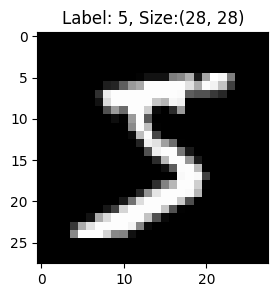

In [5]:
image, label = train_dataset[0]

plt.figure(figsize=(3,3))

plt.imshow(image, cmap="gray")
plt.title(f"Label: {label}, Size:{image.size}")

Let's take a look at more data.

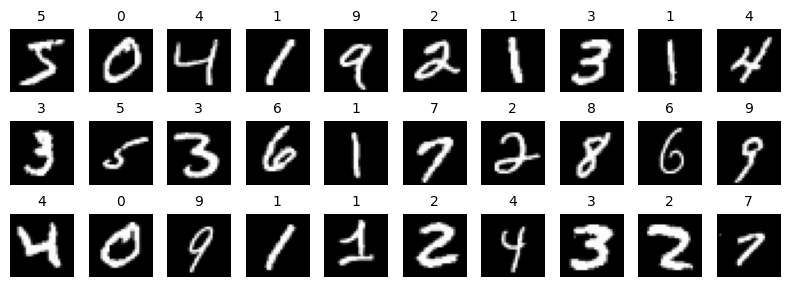

In [6]:
plt.figure(figsize=(8,3))

for i in range(30):
    plt.subplot(3, 10, i+1)
    image, label = train_dataset[i]
    plt.imshow(image, cmap="gray")
    plt.title(f"{label}", size=10)
    plt.axis("off")
plt.tight_layout()

### torch.tensor

To work with data in PyTorch, it needs to be in the `torch.tensor` format. You can get the data in `torch.tensor` format by specifying the `transform=transforms.ToTensor()` parameter when loading it from `torchvision.datasets`.

In [7]:
from torchvision import transforms

train_dataset = MNIST(root="mnist", train=True, download=False, transform=transforms.ToTensor())
test_dataset = MNIST(root="mnist", train=False, download=False, transform=transforms.ToTensor())

### DataLoader

We create `DataLoader` objects to feed the dataset into a PyTorch model, just as we did with the Iris dataset.

In [8]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

That's it for data preparation!

## Model Building

### Model Architecture

The next step is to build a Vision Transformer (ViT) model. The ViT architecture depicted in [the original paper](https://arxiv.org/abs/2010.11929) is as follows.

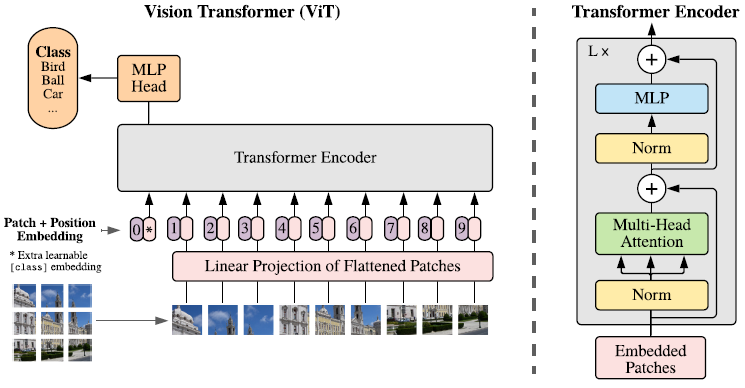

In [9]:
import torch
import torch.nn as nn

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=64, heads=4):
        super().__init__()
        self.heads = heads
        self.head_dim = d_model // heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x):
        B, N, C = x.shape
        q = self.q_proj(x).view(B, N, self.heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, N, self.heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, N, self.heads, self.head_dim).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        attn_weights = torch.softmax(scores, dim=-1)
        attn_out = torch.matmul(attn_weights, v)
        attn_out = attn_out.transpose(1, 2).contiguous().view(B, N, C)
        attn_out = self.out_proj(attn_out)

        return attn_out, attn_weights

In [10]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model=64, heads=4, dim_feedforward=128):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.GELU(),
            nn.Linear(dim_feedforward, d_model)
        )

    def forward(self, x):
        attn_out, weights = self.attn(self.norm1(x))
        x = x + attn_out
        x = x + self.ffn(self.norm2(x))
        return x, weights

In [11]:
class VisionTransformer(nn.Module):
    def __init__(self, image_size=28, patch_size=7, num_classes=10, embed_dim=64, depth=3, heads=4):
        super().__init__()
        self.patch_size = patch_size # P
        self.num_patches = (image_size // patch_size) ** 2

        self.patch_embed = nn.Linear(1 * patch_size * patch_size, embed_dim)

        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.randn(1, self.num_patches + 1, embed_dim))

        self.layers = nn.ModuleList([
            TransformerEncoderLayer(embed_dim, heads) for _ in range(depth)
        ])

        self.mlp_head = nn.Linear(embed_dim, num_classes)


    def forward(self, x):
        B, C, H, W = x.shape

        x = x.unfold(2, self.patch_size, self.patch_size).unfold(3, self.patch_size, self.patch_size)
        x = x.contiguous().view(B, -1, C*self.patch_size * self.patch_size)
        x = self.patch_embed(x)

        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.pos_embed

        self.attn_weights = []                         # empty list for the attention weights
        for layer in self.layers:
            x, weights = layer(x)                      # this time we keep the weights
            self.attn_weights.append(weights.detach())

        cls_output = x[:, 0, :]
        out = self.mlp_head(cls_output)

        return out

One line in `forward()` is only for us, not for the classification:

```
self.attn_weights = []
for layer in self.layers:
    x, weights = layer(x)
    self.attn_weights.append(weights.detach())
```

Each encoder layer also returns its **attention weights**, so here the model saves them in a list. We will use this list in the **Attention Visualization** section at the end of this notebook, to see which patches the model looked at. `.detach()` means "we do not need gradients for these values", so this does not make the training slower.

Let's check if the model can be loaded onto the GPU.

In [12]:
model = VisionTransformer().to(device)

for dummy_images, dummy_labels in train_loader:
    dummy_images = dummy_images.to(device)
    output = model(dummy_images)
    print("output size", output.shape)
    break

output size torch.Size([64, 10])


Let's visualize the model architecture using the torchinfo package. This is a valuable tool for understanding how the data shape evolves as it moves through the model.

In [13]:
! pip install torchinfo
from torchinfo import summary

for x_batch, _ in train_loader:
    break

input_shape = x_batch.shape
print("\ninput data shape:", input_shape)

summary(model, input_shape)


input data shape: torch.Size([64, 1, 28, 28])


Layer (type:depth-idx)                   Output Shape              Param #
VisionTransformer                        [64, 10]                  1,152
├─Linear: 1-1                            [64, 16, 64]              3,200
├─ModuleList: 1-2                        --                        --
│    └─TransformerEncoderLayer: 2-1      [64, 17, 64]              --
│    │    └─LayerNorm: 3-1               [64, 17, 64]              128
│    │    └─MultiHeadAttention: 3-2      [64, 17, 64]              16,640
│    │    └─LayerNorm: 3-3               [64, 17, 64]              128
│    │    └─Sequential: 3-4              [64, 17, 64]              16,576
│    └─TransformerEncoderLayer: 2-2      [64, 17, 64]              --
│    │    └─LayerNorm: 3-5               [64, 17, 64]              128
│    │    └─MultiHeadAttention: 3-6      [64, 17, 64]              16,640
│    │    └─LayerNorm: 3-7               [64, 17, 64]              128
│    │    └─Sequential: 3-8              [64, 17, 64]          

## How the ViT works

In this section, we will follow the data step by step, from one MNIST image to the final prediction. We will do exactly the same calculations as the `VisionTransformer` class above, but one line at a time, so that we can see what happens inside the model.

The main idea of the ViT is simple:

1. **Cut** the image into small patches.
2. **Convert** each patch into a vector (a list of numbers).
3. **Let the patches look at each other** with self-attention.
4. **Read one special vector** (the class token) to decide the answer.

A useful analogy: a sentence is a sequence of words, and for the ViT an image is a sequence of patches. The Transformer does not care whether the input came from text or from an image. It only sees a sequence of vectors.

While you read the code, please watch the **shape** of the tensor `x` at every step. Following the shape is the easiest way to understand this model.

### Input Data

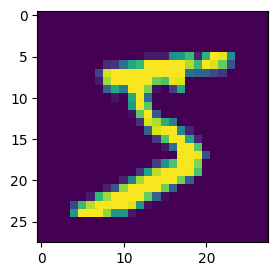

In [14]:
import torchvision.transforms.functional as TF

image, label = train_dataset[0]

plt.figure(figsize=(3, 3))
plt.imshow(TF.to_pil_image(image))

A PyTorch model always expects a *batch* of images, not a single image. So we add one more dimension at the front with `unsqueeze(0)`. After that, the shape of `x` is `(B, C, H, W)`.

| symbol | meaning | value here |
|---|---|---|
| B | batch size (how many images) | 1 |
| C | channels (1 = gray, 3 = color) | 1 |
| H | height in pixels | 28 |
| W | width in pixels | 28 |

In [15]:
# Let's say we have the input data x with its batch size of 1.
x = image.unsqueeze(0)
B, C, H, W = x.shape
print("Batch Size (B):", B)
print("Channel (C):", C)
print("Height (H):", H)
print("Width (W):", W)

Batch Size (B): 1
Channel (C): 1
Height (H): 28
Width (W): 28


#### Step 1: Split the image into patches

A Transformer cannot read a 2D image directly. It can only read a sequence. So we cut the image into small squares called **patches**.

The image is 28x28 pixels and the patch size is 7x7 pixels. So we get 28 / 7 = 4 patches in each direction, and 4 x 4 = **16 patches** in total.

`unfold(dimension, size, step)` cuts a tensor into blocks. We use it twice: once for the height (dimension 2) and once for the width (dimension 3).

Each patch works like one word in a sentence. Our image is now a "sentence" made of 16 words.

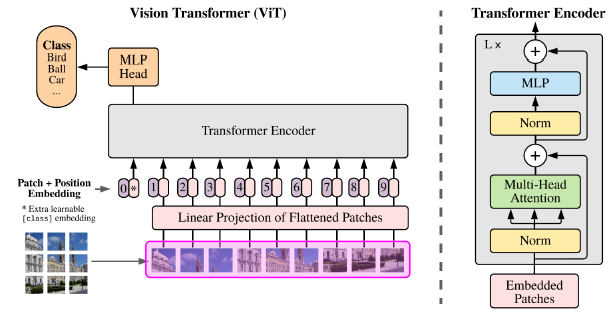

torch.Size([1, 1, 4, 4, 7, 7])


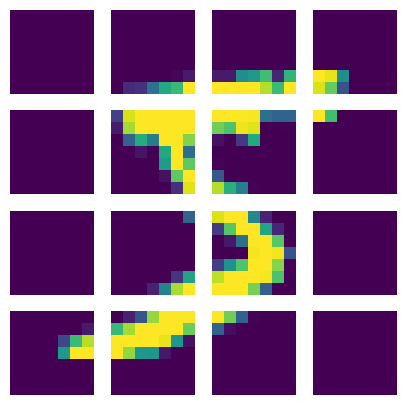

In [16]:
# Split the image into 4x4 patches. The size of each patch is 7x7.
patch_size = 7
x = x.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
print(x.size())

plt.figure(figsize=(5, 5))
for i in range(4):
    for j in range(4):
        plt.subplot(4, 4, i*4 + j + 1)
        patch = x[0, 0, i, j, :, :].view(patch_size, patch_size)
        plt.imshow(TF.to_pil_image(patch))
        plt.axis("off")


#### Step 2: Flatten each patch

Each patch is still a small 2D image of 7x7 pixels. We stretch it into a 1D vector of 7 x 7 = 49 numbers.

Now `x` has the shape `(1, 16, 49)`: 1 image, 16 patches, and 49 numbers for each patch. This is exactly the shape that a Transformer wants: **(batch, sequence length, features)**.

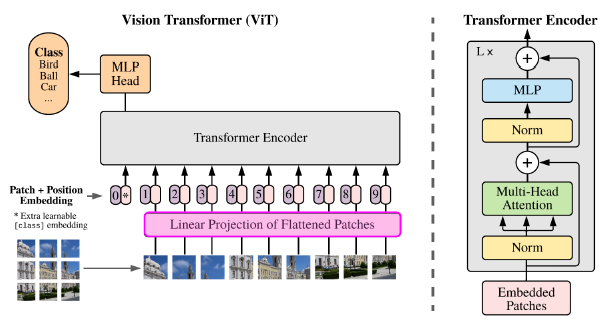

Text(0.5, 1.0, 'Flattened Patches: torch.Size([1, 16, 49])')

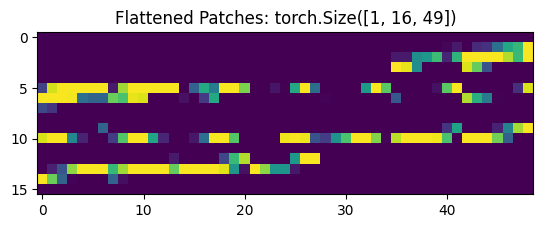

In [17]:
# flatten the patches into a 16x49 tensor
x = x.contiguous().view(B, -1, C*patch_size * patch_size)
x.size()
plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"Flattened Patches: {x.size()}")

#### Step 3: Patch embedding

Raw pixel values are not a good input for a Transformer. We want a vector that the model can learn to make useful. So we send each patch through one linear (fully connected) layer:

$\boldsymbol{z} = W\boldsymbol{p} + \boldsymbol{b}$

This layer converts 49 numbers into `embed_dim = 64` numbers. The result is called the **patch embedding**, and the shape of `x` becomes `(1, 16, 64)`.

The *same* linear layer is used for all 16 patches, in the same way that a CNN uses the same filter everywhere in the image.

Text(0.5, 1.0, 'Embeded Patches: torch.Size([1, 16, 64])')

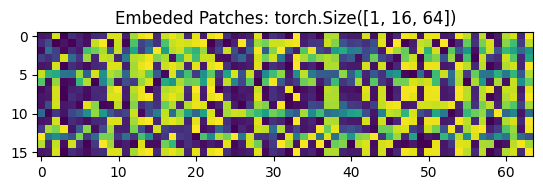

In [18]:
# Embed the flattened patches into 16x64 vector
embed_dim = 64
patch_embed = nn.Linear(1 * patch_size * patch_size, embed_dim)
x = patch_embed(x)
x.size()
plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"Embeded Patches: {x.size()}")

`W` and `b` are **learnable parameters**. `requires_grad = True` means that PyTorch will compute gradients for them, so they are updated during training. In other words, we do not design how to convert a patch into a vector; the model learns it by itself.

In [19]:
name, param = patch_embed.parameters()
param.requires_grad

True

#### Step 4: Add the class token

The 16 patch embeddings describe 16 small parts of the image. But for classification we need one single vector that describes the **whole** image.

The ViT solves this in a clever way. It adds one extra vector called the **class token** (`cls_token`). This vector does not come from the image. It starts as random numbers, and it is a learnable parameter, so it is trained together with the other weights.

You can think of the class token as an empty notebook. While the model runs, it collects information from all the patches. At the end, we read only this notebook to decide the digit.

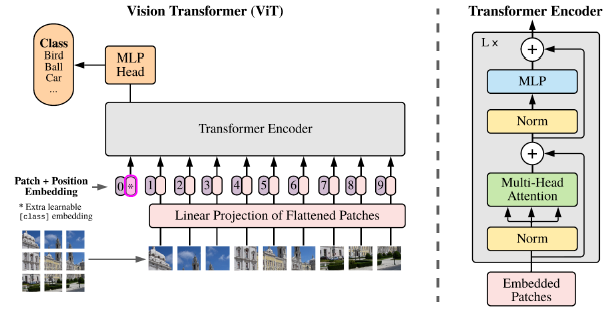

Text(0.5, 1.0, 'Class Token: torch.Size([1, 1, 64])')

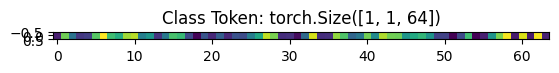

In [20]:
# Generate class token
cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
plt.imshow(TF.to_pil_image(cls_token.squeeze(0)))
plt.title(f"Class Token: {cls_token.size()}")

We put the class token at the front of the 16 patch embeddings. The sequence length becomes 16 + 1 = 17, so the shape of `x` becomes `(1, 17, 64)`.

Text(0.5, 1.0, 'Class Token + Embeded Patches: torch.Size([1, 17, 64])')

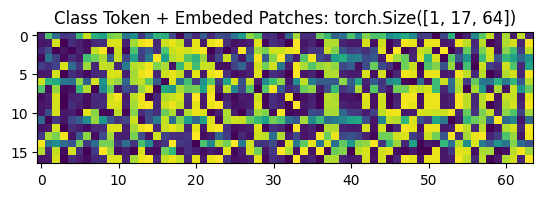

In [21]:
cls_tokens = cls_token.expand(B, -1, -1)
x = torch.cat((cls_tokens, x), dim=1)
plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"Class Token + Embeded Patches: {x.size()}")

#### Step 5: Add the position embedding

Self-attention has no sense of order. If we shuffle the patches, the output does not change. This is a problem for images, because the position of a patch is important. (Think about the digits 6 and 9!)

To tell the model where each patch came from, we add a **position embedding**: one learnable vector for each of the 17 positions. Its shape is `(1, 17, 64)`, the same as `x`. The model learns these vectors during training, so it finds out by itself which positions are close to each other.

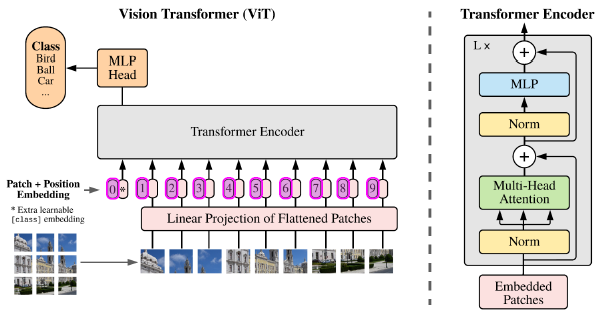

Text(0.5, 1.0, 'Position Embedding Vectors: torch.Size([1, 17, 64])')

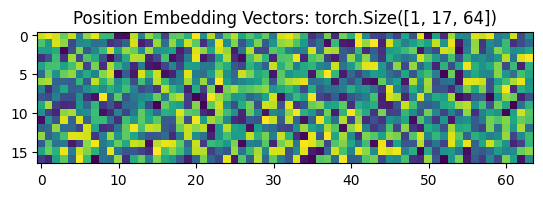

In [22]:
# generate position embedding vectors
image_size = 28
num_patches = (image_size // patch_size) ** 2
pos_embed = nn.Parameter(torch.randn(1, num_patches + 1, embed_dim))

plt.imshow(TF.to_pil_image(pos_embed.squeeze(0)))
plt.title(f"Position Embedding Vectors: {pos_embed.size()}")

We simply **add** the position embedding to `x` (we do not concatenate it), so the shape stays `(1, 17, 64)`.

This tensor is the input of the Transformer Encoder. Let's summarize the preparation:

`(1, 1, 28, 28)` image -> `(1, 16, 49)` flattened patches -> `(1, 16, 64)` patch embeddings -> `(1, 17, 64)` with the class token and the position information.

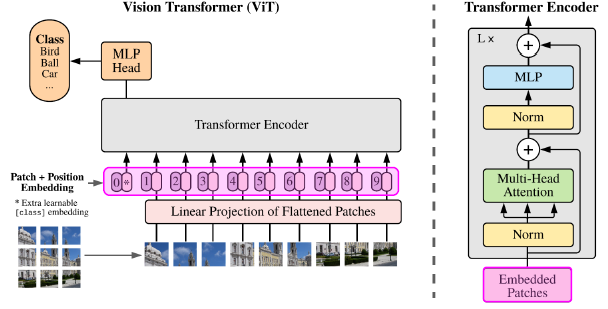

Text(0.5, 1.0, '(Class Token + Embeded Patches)+Position Embedding Vectors: torch.Size([1, 17, 64])')

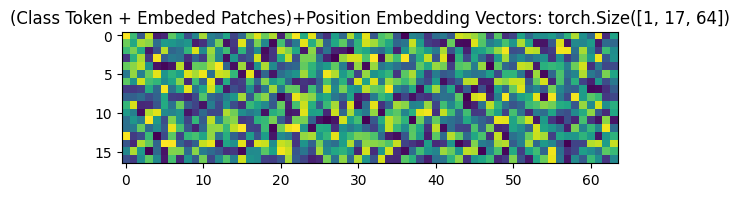

In [23]:
# This is the input data for the Transformer Encoder
x = x + pos_embed
plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"(Class Token + Embeded Patches)+Position Embedding Vectors: {x.size()}")

### Transformer Encoder

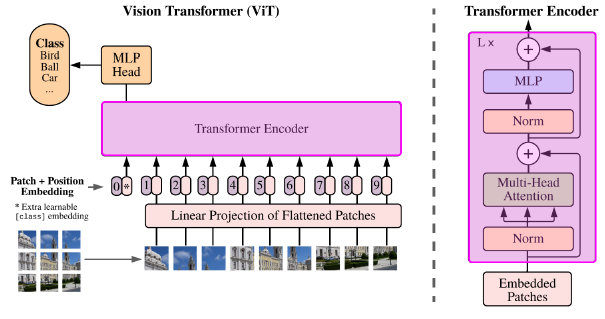

The Transformer Encoder is the main part of the model. One encoder layer has four steps:

Step 1. Layer Normalization

Step 2. Multi-Head Self-Attention

Step 3. Layer Normalization

Step 4. Feed Forward Network (a small MLP)

A **residual connection** (`x = x + ...`) is used after step 2 and after step 4.

One important point: the shape of `x` never changes inside the encoder. It is `(1, 17, 64)` at the input and `(1, 17, 64)` at the output. Thanks to this, we can stack the same layer as many times as we want.

#### Step 1: Layer Normalization 1
**Layer Normalization** rescales each token vector so that its mean becomes 0 and its standard deviation becomes 1. It is applied to each of the 17 vectors independently, over their 64 features.

Normalization keeps the numbers in a good range, which makes the training faster and more stable. Note that we normalize *before* the attention. This design is called "Pre-LN", and it is used in most modern Transformers.

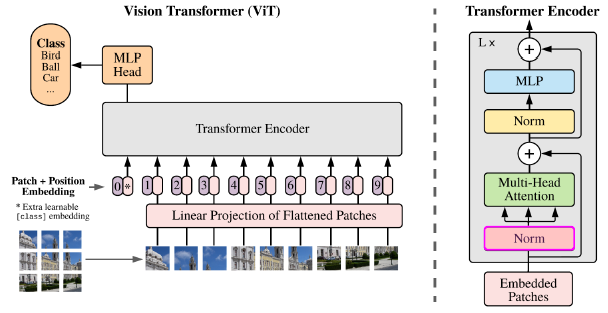

Text(0.5, 1.0, 'x after Layer Normalization 1: torch.Size([1, 17, 64])')

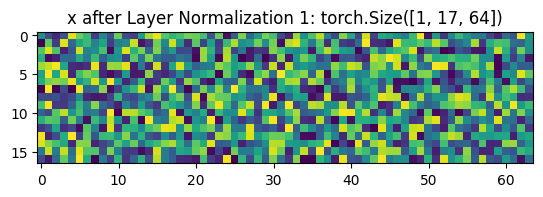

In [24]:
# Layer Normalization 1
d_model = embed_dim # 64
norm1 = nn.LayerNorm(d_model)

x = norm1(x)
plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"x after Layer Normalization 1: {x.size()}")

#### Step 2: Multi-Head Attention

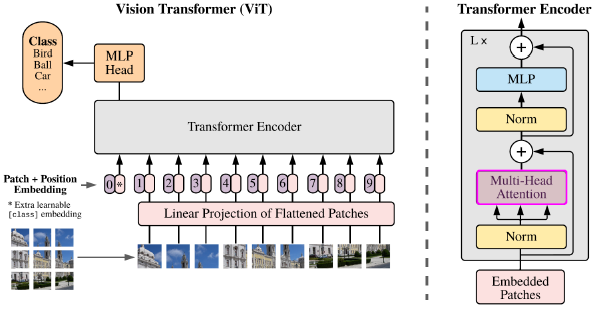

##### Query, Key and Value

In self-attention, every token looks at all the tokens and collects the information it needs. To do this, each token creates three different vectors from its own vector.

| vector | name | role (search engine analogy) |
|---|---|---|
| Q | Query | what I am looking for |
| K | Key | what I can offer |
| V | Value | the information I actually give |

Q, K and V are made by three different linear layers, so the model learns three different views of the same token.

We also use **multi-head** attention. Here `d_model = 64` and `heads = 4`, so each head uses 64 / 4 = 16 features (`head_dim`). Each head can watch a different kind of relation; for example, one head may focus on the shape of a stroke and another head may focus on the position. `view()` and `transpose()` only reshape the data, and the shape of `q` becomes `(B, heads, N, head_dim)` = `(1, 4, 17, 16)`.

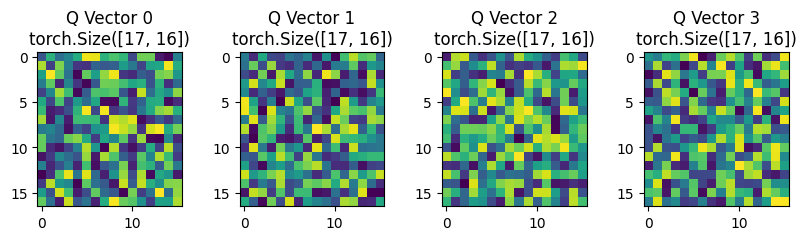

In [25]:
# Q vector
heads = 4
head_dim = d_model // heads # 64 // 4 = 16
B, N, C = x.shape

q_proj = nn.Linear(d_model, d_model)
q = q_proj(x).view(B, N, heads, head_dim).transpose(1, 2)

plt.figure(figsize=(10, 2))
for i in range(heads):
    qi = q[0, i, :, :]
    plt.subplot(1, 4, i+1)
    plt.imshow(TF.to_pil_image(qi.squeeze(0)))
    plt.title(f"Q Vector {i}\n{qi.size()}")


The Key vectors are made in the same way, with their own linear layer `k_proj`.

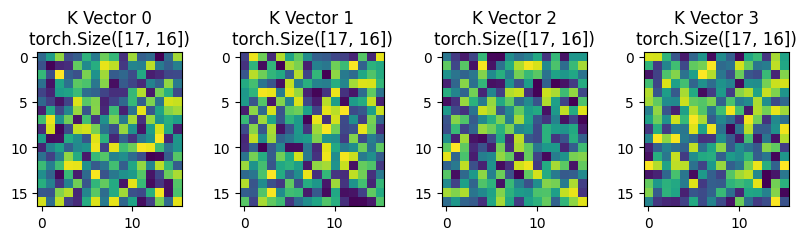

In [26]:
# K vector
k_proj = nn.Linear(d_model, d_model)
k = k_proj(x).view(B, N, heads, head_dim).transpose(1, 2)

plt.figure(figsize=(10, 2))
for i in range(heads):
    ki = k[0, i, :, :]
    plt.subplot(1, 4, i+1)
    plt.imshow(TF.to_pil_image(ki.squeeze(0)))
    plt.title(f"K Vector {i}\n{ki.size()}")

The Value vectors are also made in the same way, with their own linear layer `v_proj`.

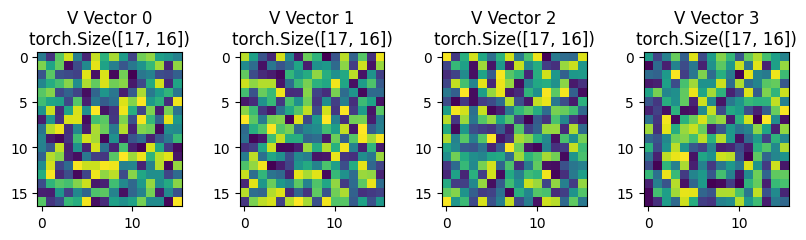

In [27]:
# V vector
v_proj = nn.Linear(d_model, d_model)
v = v_proj(x).view(B, N, heads, head_dim).transpose(1, 2)

plt.figure(figsize=(10, 2))
for i in range(heads):
    vi = v[0, i, :, :]
    plt.subplot(1, 4, i+1)
    plt.imshow(TF.to_pil_image(vi.squeeze(0)))
    plt.title(f"V Vector {i}\n{vi.size()}")

Determine self attention score

$\mathrm{Attention}(\boldsymbol{Q}, \boldsymbol{K}, \boldsymbol{V}) = \mathrm{softmax}\left(\dfrac{\boldsymbol{Q}\boldsymbol{K}^{T}}{\sqrt{d_k}}\right)\boldsymbol{V}$

Let's read this formula from the inside.

1. $\boldsymbol{Q}\boldsymbol{K}^{T}$ : the dot product between every query and every key. A large value means "these two tokens are strongly related". For each head we get a 17 x 17 table of scores.
2. $\sqrt{d_k}$ : we divide the scores by the square root of `head_dim`. Here `head_dim` is 16, so we divide the scores by 4. Without this, the scores become too large, softmax becomes too sharp, and the gradients become too small to learn.
3. $\mathrm{softmax}$ : each row of the table is converted into weights between 0 and 1 whose sum is 1. This is "how much attention token *i* pays to token *j*".
4. $\times \boldsymbol{V}$ : each token takes the weighted average of the Value vectors of all the tokens.

The 17 x 17 table after the softmax is called the **attention weights**. We will draw this table as a picture in the **Attention Visualization** section at the end of this notebook.

So the new vector of each token is a mixture of the information of all the tokens, and the model itself decides the mixing ratio. This is the biggest difference from a CNN: a CNN can only see a small local area in its first layer, but the ViT can look at the whole image from the very first layer.

torch.Size([1, 4, 17, 16])


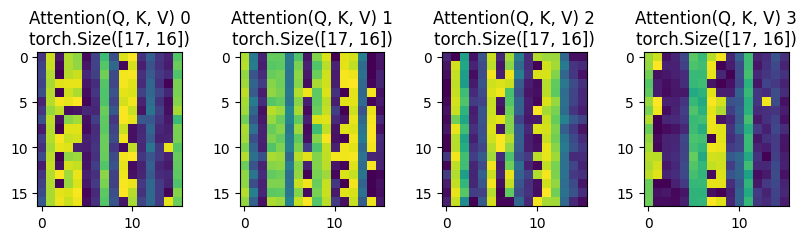

In [28]:
scores = torch.matmul(q, k.transpose(-2, -1)) / (head_dim ** 0.5)
attn_weights = torch.softmax(scores, dim=-1)
attn_out = torch.matmul(attn_weights, v)

print(attn_out.size())

plt.figure(figsize=(10, 2))
for i in range(heads):
    attn_out_i = attn_out[0, i, :, :]

    plt.subplot(1, 4, i+1)
    plt.imshow(TF.to_pil_image(attn_out_i.squeeze(0)))
    plt.title(f"Attention(Q, K, V) {i}\n{attn_out_i.size()}")


# attn_out = attn_out.transpose(1, 2).contiguous().view(B, N, C)

# attn_out.size()

# plt.imshow(TF.to_pil_image(attn_out.squeeze(0)))
# plt.title(f"Attention(Q, K, V)\n{attn_out.size()}")

##### Put the heads back together

The 4 heads worked separately, and each of them produced 16 features for every token. First we put them back together with `transpose()` and `view()`, so the shape becomes `(1, 17, 64)` again. This step only places the numbers side by side. It does not mix them.

That is why we then apply one more linear layer, `out_proj` (64 -> 64). Until this point the 4 heads have never talked to each other, and the 64 features are just 4 blocks of 16 features placed next to each other. `out_proj` mixes the results of all the heads into one vector, and it learns *how* to mix them during training. The shape after `out_proj` is still `(1, 17, 64)`.

In the `MultiHeadAttention` class above, this is exactly the last line of `forward()`: `return self.out_proj(attn_output), attn_weights`.

Text(0.5, 1.0, 'Attention(Q, K, V)\ntorch.Size([1, 17, 64])')

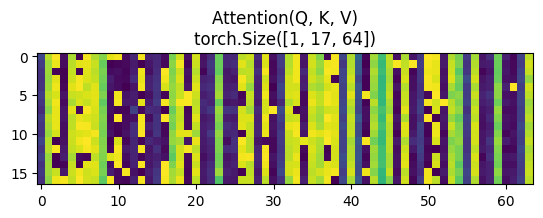

In [29]:
# put multi-head attention output together again.
attn_out = attn_out.transpose(1, 2).contiguous().view(B, N, C)

out_proj = nn.Linear(d_model, d_model)
attn_out = out_proj(attn_out)

plt.imshow(TF.to_pil_image(attn_out.squeeze(0)))
plt.title(f"Attention(Q, K, V)\n{attn_out.size()}")

##### Residual connection

`x = x + attn_out` adds the input of the attention back to its output. This is the same idea as the skip connection of ResNet.

It helps in two ways:

* The original information of each patch is not lost. The attention only *adds* new information to it.
* The gradient can flow straight through the `+` path during backpropagation, so even a deep model can be trained.

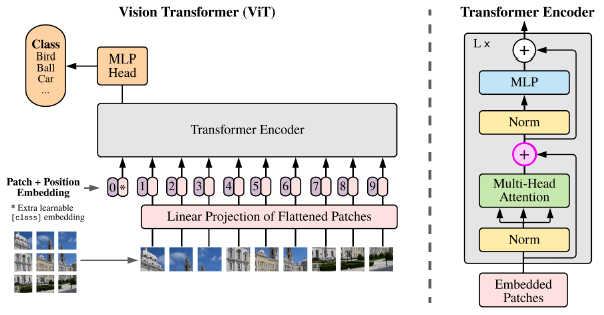

Text(0.5, 1.0, 'x + attn_out: torch.Size([1, 17, 64])')

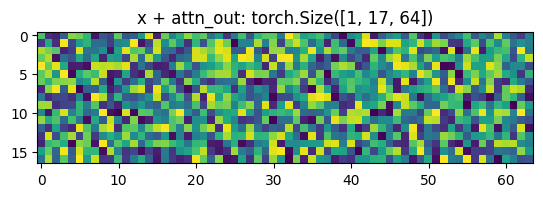

In [30]:
# Residual Connection
x = x + attn_out

plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"x + attn_out: {x.size()}")

#### Step 3: Layer Nomarization 2
Layer Normalization is applied again, this time before the feed forward network.

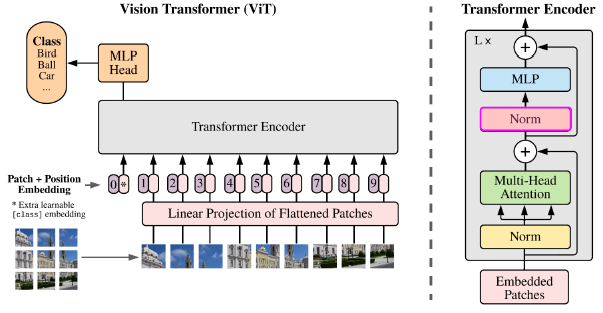

Text(0.5, 1.0, 'x after Layer Normalization 2: torch.Size([1, 17, 64])')

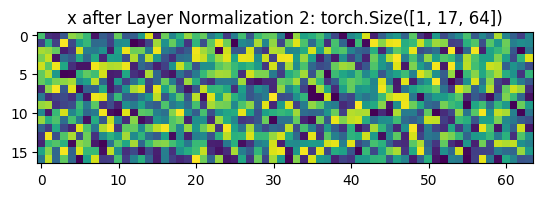

In [31]:
# Layer Normalization 2
norm2 = nn.LayerNorm(d_model)

x = norm2(x)
plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"x after Layer Normalization 2: {x.size()}")

#### Step 4: Feed Forward Network

Attention mixes information *between* the tokens. The feed forward network (FFN) processes each token *by itself*, and the same FFN is used for all 17 tokens.

It is a small MLP: 64 -> 128 -> 64, with a **GELU** activation function in the middle. GELU is a smooth version of ReLU, and it is the common choice in Transformers.

The hidden layer is wider than the input (128 > 64). This gives the model more space to transform the features before it comes back to 64 dimensions.

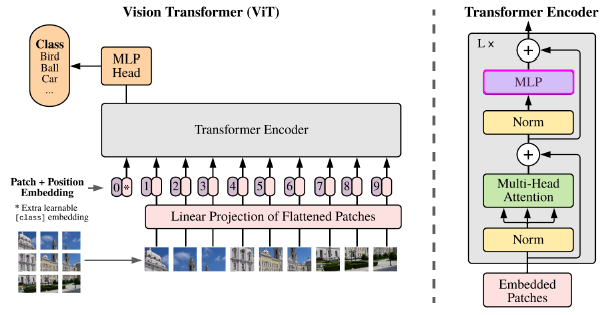

Text(0.5, 1.0, 'ffn out: torch.Size([1, 17, 64])')

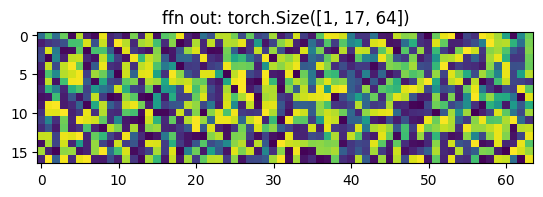

In [32]:
# Feed Forward
dim_feedforward=128

ffn = nn.Sequential(
    nn.Linear(d_model, dim_feedforward),
    nn.GELU(),
    nn.Linear(dim_feedforward, d_model)
)

ffn_out = ffn(x)

plt.imshow(TF.to_pil_image(ffn_out.squeeze(0)))
plt.title(f"ffn out: {ffn_out.size()}")

One more residual connection. The output shape is `(1, 17, 64)`, exactly the same as the input shape of this encoder layer. This is why we can repeat the layer again and again.

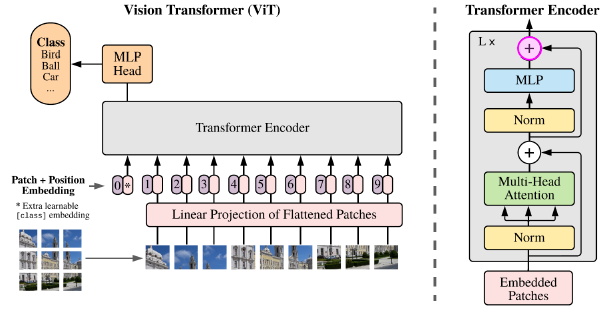

Text(0.5, 1.0, 'x + ffn_out: torch.Size([1, 17, 64])')

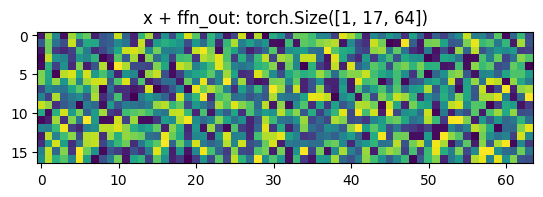

In [33]:
# Residual Connection
x = x + ffn_out

plt.imshow(TF.to_pil_image(x.squeeze(0)))
plt.title(f"x + ffn_out: {x.size()}")

The processes in the transformer encoder are repeated with the number of depth.



```
class VisionTransformer(nn.Module):
    def __init__(self, image_size=28, patch_size=7, num_classes=10, embed_dim=64, depth=3, heads=4):
        ...
        self.layers = nn.ModuleList([
            TransformerEncoderLayer(embed_dim, heads) for _ in range(depth)
        ])
        ...


    def forward(self, x):
        ...
        for layer in self.layers:
            x, weights = layer(x)
        ...
```



Each encoder layer returns two things: the new `x` and the attention `weights`. The model does not need the weights to classify the digit, but it saves them in `self.attn_weights`, so that we can look at them later in the **Attention Visualization** section.

In our model `depth = 3`, so the four steps above are repeated 3 times. Each layer has its own weights, and the shape of `x` stays `(1, 17, 64)` all the way. Deeper layers can combine information over wider areas of the image.

### Classifier

After the encoder, `x` still has 17 tokens. For the classification we use only the first one: the **class token**.

Its shape is `(1, 64)`. Because of self-attention, this single vector has already collected information from all 16 patches, so we can use it as a summary of the whole image. The 16 patch tokens are simply not used here.

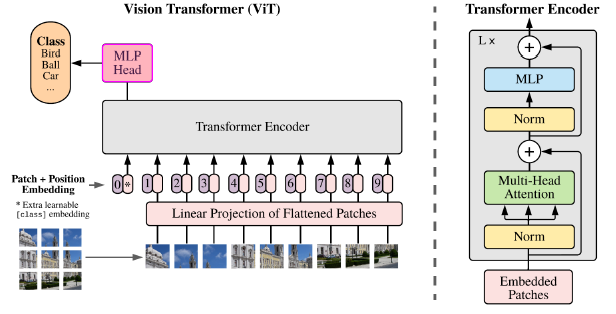

torch.Size([1, 64])


Text(0.5, 1.0, 'Class Embedding output: torch.Size([1, 64])')

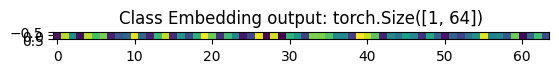

In [34]:
# Take class embedding output
cls_out = x[:, 0, :]
print(cls_out.size())
plt.imshow(TF.to_pil_image(cls_out.unsqueeze(0)))
plt.title(f"Class Embedding output: {cls_out.size()}")

The last step is one linear layer that converts the 64 features into `num_classes = 10` numbers. These 10 numbers are called **logits**: one score for each digit from 0 to 9. The digit with the largest logit is the prediction of the model.

(We do not need a softmax layer here, because `nn.CrossEntropyLoss` applies softmax internally during training.)

The values printed below are almost random, because the layers in this section have not been trained yet. We will train the model in the next section.

In [35]:
# MLP classifier
num_classes = 10
mlp_head = nn.Linear(embed_dim, num_classes)

out = mlp_head(cls_out)
print(out)

tensor([[-0.7026,  0.6351,  0.1550,  0.7278,  0.4088,  0.9537,  0.6537, -0.7454,
         -0.2099,  0.6617]], grad_fn=<AddmmBackward0>)


### Summary of the data flow

| step | operation | shape of `x` |
|---|---|---|
| 0 | input image | (1, 1, 28, 28) |
| 1 | split into 4x4 patches of 7x7 | (1, 1, 4, 4, 7, 7) |
| 2 | flatten each patch | (1, 16, 49) |
| 3 | patch embedding (Linear 49 -> 64) | (1, 16, 64) |
| 4 | add the class token | (1, 17, 64) |
| 5 | add the position embedding | (1, 17, 64) |
| 6 | Transformer Encoder x `depth` | (1, 17, 64) |
| 7 | take the class token only | (1, 64) |
| 8 | MLP head (Linear 64 -> 10) | (1, 10) |

If you can explain this table by yourself, you understand how a Vision Transformer works.

## Training

### Loss Function

We use the cross-entropy loss as the loss function because this is a classification task.

In [36]:
loss_func = nn.CrossEntropyLoss()

### Optimizer

We use the Adam optimizer.

In [37]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters(), lr=1E-3)

### Training Loop
Now, we will train the ViT model using the MNIST dataset. The training loop is actually identical to the one we used last week.







In [38]:
import torch.optim as optim

model = VisionTransformer().to(device)                 # load model to GPU
loss_func = nn.CrossEntropyLoss()                      # set loss function
optimizer = optim.Adam(model.parameters(), lr=1E-3)    # set optimizer

epochs = 10

# create empty lists for saving metrics during training
train_loss_list = []
train_accuracy_list = []
test_loss_list = []
test_accuracy_list = []

for epoch in range(epochs):
    print("-----------------------------")
    print(f"Epoch {epoch+1}/{epochs}")

    # initialize metrics
    train_correct_count = 0
    train_accuracy = 0
    train_loss = 0
    test_correct_count = 0
    test_accuracy = 0
    test_loss = 0

    #--- Training Phase ---#
    model.train()    # set model to training mode

    for x_batch, y_batch in tqdm(train_loader): # take mini batch data from train_loader

        x_batch = x_batch.to(device)     # load x_batch data on GPU
        y_batch = y_batch.to(device)     # load y_batch data on GPU

        optimizer.zero_grad()                  # reset gradients to 0
        p_batch = model(x_batch)               # do prediction
        loss = loss_func(p_batch, y_batch)     # measure loss
        loss.backward()                        # calculate gradients
        optimizer.step()                       # update model parameters

        train_loss += loss.item()                                # accumulate loss value
        p_batch_label = torch.argmax(p_batch, dim=1)             # convert p_batch vector to p_batch_label
        train_correct_count += (p_batch_label == y_batch).sum()  # count up number of correct predictions
    #----------------------#

    #--- Evaluation Phase ---#
    with torch.no_grad():   # disable autograd for saving memory usage
        model.eval()        # set model to evaluation mode

        for x_batch, y_batch in tqdm(test_loader):   # take mini batch data from test_loader

            x_batch = x_batch.to(device)     # load x_batch data on GPU
            y_batch = y_batch.to(device)     # load y_batch data on GPU

            p_batch = model(x_batch)              # do prediction
            loss = loss_func(p_batch, y_batch)    # measure loss

            test_loss += loss.item()                                # accumulate loss value
            p_batch_label = torch.argmax(p_batch, dim=1)            # convert p_batch vector to p_batch_label
            test_correct_count += (p_batch_label == y_batch).sum()  # count up number of correct predictions
    #------------------------#

    train_accuracy = train_correct_count/len(train_dataset)   # determine accuracy for training data
    test_accuracy = test_correct_count/len(test_dataset)      # determine accuracy for test data
    train_loss = train_loss/len(train_loader)                 # determine loss for training data
    test_loss = test_loss/len(test_loader)                    # determine loss for test data

    # show and store metrics
    print(f"Train: Accuracy={train_accuracy:.3f} Loss={train_loss:.3f}, Test: Accuracy={test_accuracy:.3f} Loss={test_loss:.3f}")
    train_accuracy_list.append(train_accuracy.item())
    train_loss_list.append(train_loss)
    test_accuracy_list.append(test_accuracy.item())
    test_loss_list.append(test_loss)

-----------------------------
Epoch 1/10


  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Train: Accuracy=0.865 Loss=0.406, Test: Accuracy=0.954 Loss=0.149
-----------------------------
Epoch 2/10


  0%|          | 0/938 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

Train: Accuracy=0.985 Loss=0.045, Test: Accuracy=0.979 Loss=0.070
-----------------------------
Epoch 10/10


  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Train: Accuracy=0.987 Loss=0.040, Test: Accuracy=0.978 Loss=0.080


### Learning Curves

Let's plot the accuracy curves for both the training and test data.

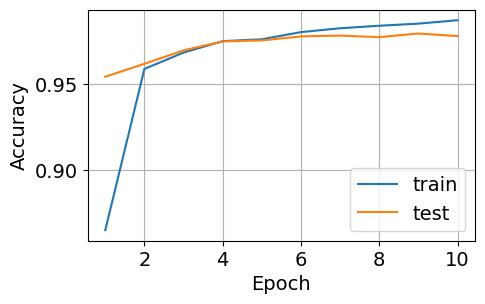

In [39]:
plt.figure(figsize=(5,3))
plt.rcParams["font.size"]=14
plt.plot(np.arange(epochs)+1, train_accuracy_list, label="train")
plt.plot(np.arange(epochs)+1, test_accuracy_list, label="test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid()
plt.legend()

Also let's plot the loss curves for the training and test data.

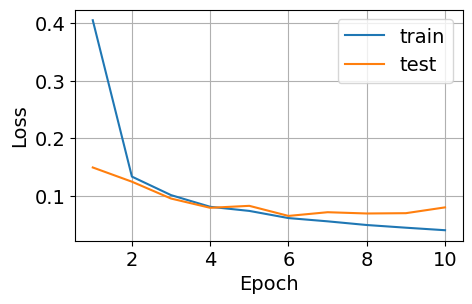

In [40]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(epochs)+1, train_loss_list, label="train")
plt.plot(np.arange(epochs)+1, test_loss_list, label="test")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.legend()

## Evaluation

### Test Accuracy

Let's check the accuracy of the model for all of the test data.

In [41]:
test_accuracy = 0

y_test_all = np.array([])
p_label_all = np.array([])

with torch.no_grad():    # disable autograd
    model.eval()         # set model to evaluation mode

    for x_batch, y_batch in test_loader:    # take mini batch data from train_loader
        x_batch = x_batch.to(device)        # transfer x_batch to gpu
        y_batch = y_batch.to(device)        # transfer y_batch to gpu
        p_batch = model(x_batch)            # do prediction

        p_batch_label = torch.argmax(p_batch, dim=1)       # convert p_batch vector to p_batch_label
        test_accuracy += (p_batch_label == y_batch).sum()  # count up number of correct predictions

        y_test_all = np.append(y_test_all, y_batch.to("cpu").numpy())          # append y_batch in y_test_all
        p_label_all = np.append(p_label_all, p_batch_label.to("cpu").numpy())  # append p_batch_label in p_label_all

test_accuracy = test_accuracy/len(test_dataset)      # determine accuracy for test data
print(f"Test Accuracy = {test_accuracy:.3f}")

Test Accuracy = 0.978


### Confusion Matrix

Then let's check the confusion matrix.

Text(0.5, 1.0, 'confusion matrix')

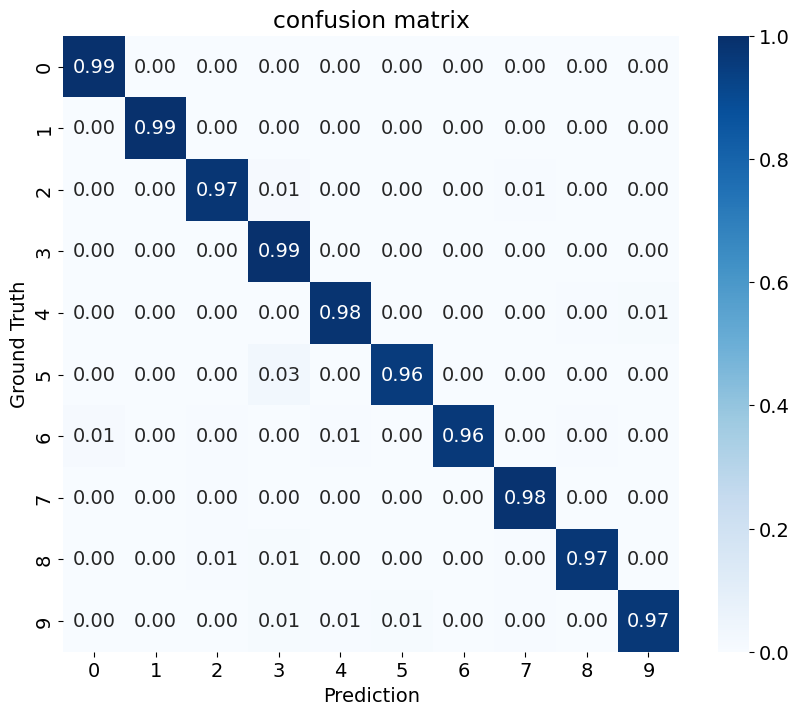

In [42]:
from sklearn.metrics import confusion_matrix
import numpy as np

cmx = confusion_matrix(y_test_all, p_label_all)

cmx_pct = np.zeros(cmx.shape)

for i in range(cmx.shape[0]):
    for j in range(cmx.shape[1]):
        cmx_pct[i, j] = cmx[i, j]/cmx[i, :].sum()

plt.figure(figsize=(10,8))
labels = np.arange(10)

sns.heatmap(cmx_pct, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=labels, yticklabels=labels, square=True)

plt.ylabel("Ground Truth")
plt.xlabel("Prediction")
plt.title("confusion matrix")

### Predictions for Test Data

Let's see predictions for some test data.

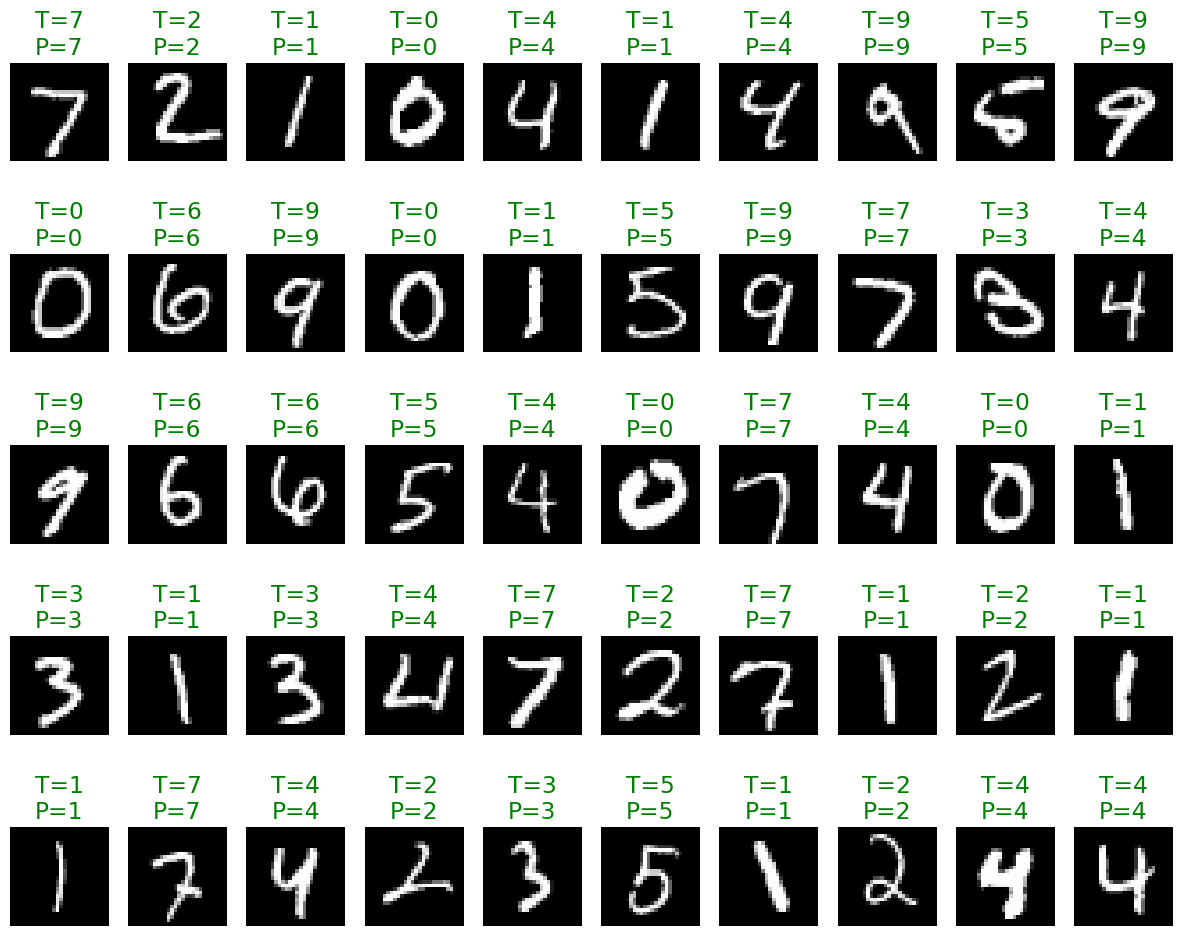

In [43]:
plt.figure(figsize=(15, 12))

for i in range(50):
    image, _ = test_dataset[i]
    image = np.transpose(image, (1,2,0))
    plt.subplot(5, 10, i+1)
    plt.imshow(image, cmap="gray")

    true_class = y_test_all[i]
    pred_class = p_label_all[i]
    if true_class == pred_class:
        color = "green"
    else:
        color = "red"
    plt.title(f"T={true_class:.0f}\nP={pred_class:.0f}", color=color)
    plt.axis("off")


## Attention Visualization

A CNN is like a black box. It is not easy to know where the model looked. A ViT is a little kinder to us.

Inside the self-attention, the model makes **attention weights**. They show how much each token looked at each other token. If we look at the weights of the **class token**, we can see which patches the model used to decide the answer.

Our `VisionTransformer` already keeps these weights for us. In `forward()`, every encoder layer returns the new `x` **and** its attention `weights`, and the model saves the weights in a list:

```
self.attn_weights = []
for layer in self.layers:
    x, weights = layer(x)
    self.attn_weights.append(weights.detach())
```

So we do not need any special code in this section. We just give an image to the model, and then read `model.attn_weights`.

Two small points about this list:

* It has one item for each encoder layer. Our model has `depth = 3`, so the list has 3 items.
* It always holds the weights of the **last** data we gave to the model. If we call `model(x)` again with another image, the weights of the old image are gone.

Let's take one image from the test dataset and get its attention weights. You can change `index` to try other images.

true label: 7
predicted label: 7
number of encoder layers: 3
shape of the weights of one layer: torch.Size([1, 4, 17, 17])


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

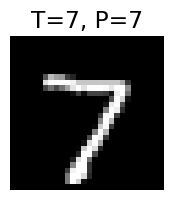

In [44]:
model.eval()                          # set model to evaluation mode

index = 0                             # which test image do we use?
image, label = test_dataset[index]
x = image.unsqueeze(0).to(device)     # add the batch dimension and send it to the GPU

with torch.no_grad():                 # no gradients here
    pred = model(x)                   # the model saves the attention weights by itself

weights_list = model.attn_weights     # the attention weights of each encoder layer
pred_label = torch.argmax(pred, dim=1).item()

n_layers = len(weights_list)          # number of encoder layers (depth)
n_heads = weights_list[0].shape[1]    # number of heads
grid_size = 28 // model.patch_size    # 4 patches in each direction

print("true label:", label)
print("predicted label:", pred_label)
print("number of encoder layers:", n_layers)
print("shape of the weights of one layer:", weights_list[0].shape)

plt.figure(figsize=(2, 2))
plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"T={label}, P={pred_label}")
plt.axis("off")

### Attention Matrix

The weights of one layer have the shape `(1, 4, 17, 17)`:

| dimension | meaning |
|---|---|
| 1 | batch size (we use only 1 image) |
| 4 | number of heads |
| 17 | the token that is **looking** (query) |
| 17 | the token that is **looked at** (key) |

Token 0 is the class token, and tokens 1 to 16 are the 16 patches.

So one row shows how much one token looks at all the tokens, and the sum of one row is always 1. In the figures below, a darker color means a larger weight.

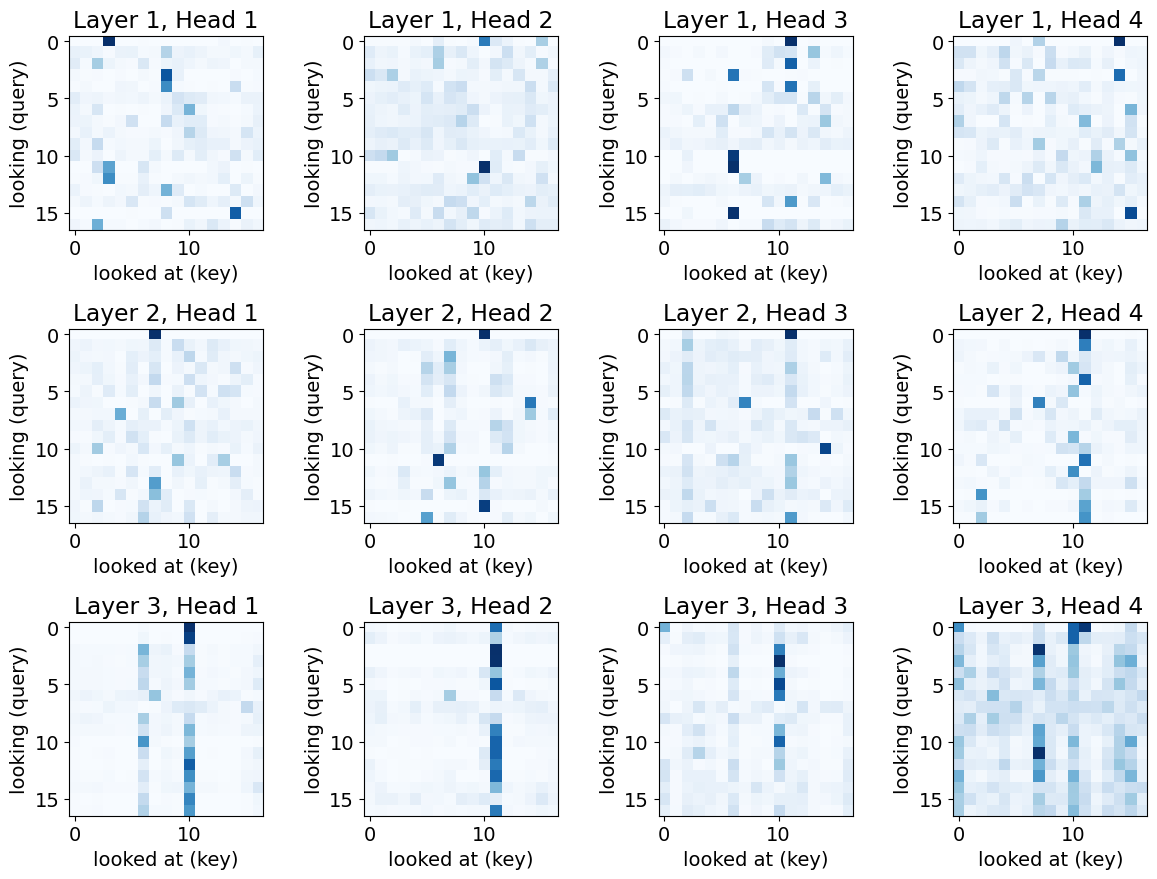

In [45]:
plt.figure(figsize=(3*n_heads, 3*n_layers))

for l in range(n_layers):
    for h in range(n_heads):
        w = weights_list[l][0, h].to("cpu").numpy()    # weights of one head: (17, 17)

        plt.subplot(n_layers, n_heads, l*n_heads + h + 1)
        plt.imshow(w, cmap="Blues", vmin=0)
        plt.title(f"Layer {l+1}, Head {h+1}")
        plt.xlabel("looked at (key)")
        plt.ylabel("looking (query)")

plt.tight_layout()

### Where does the class token look?

Row 0 of the matrix is the class token. In this row, the values `[1:]` are its attention over the 16 patches. We do not use the value `[0]`, because that is the attention to the class token itself.

The 16 patches are a 4x4 grid, so we can change these 16 values into a 4x4 image and draw it on top of the digit. **Red** means the model paid much attention there, and **blue** means little attention.

The 4 heads look at different places, so first let's take the average of the 4 heads and see each layer.

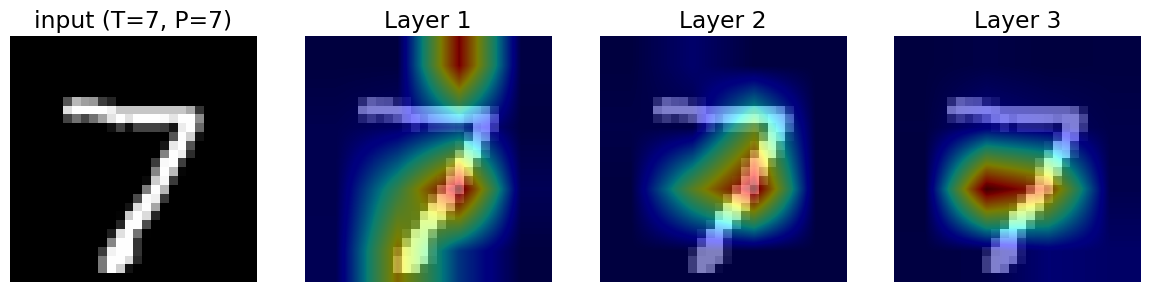

In [46]:
plt.figure(figsize=(3*(n_layers+1), 3))

# the input image
plt.subplot(1, n_layers+1, 1)
plt.imshow(image.squeeze(0), cmap="gray")
plt.title(f"input (T={label}, P={pred_label})")
plt.axis("off")

for l in range(n_layers):
    cls_attn = weights_list[l][0, :, 0, 1:].mean(dim=0)       # row 0 = class token, average over the heads
    cls_attn = cls_attn.view(grid_size, grid_size)            # 16 values -> 4x4 grid
    cls_attn = cls_attn.to("cpu").numpy()

    plt.subplot(1, n_layers+1, l+2)
    plt.imshow(image.squeeze(0), cmap="gray")                 # the digit
    plt.imshow(cls_attn, cmap="jet", alpha=0.5,               # the attention map on top of it
               extent=(-0.5, 27.5, 27.5, -0.5), interpolation="bilinear")
    plt.title(f"Layer {l+1}")
    plt.axis("off")

plt.tight_layout()

### Each head looks at a different place

Now let's look at the 4 heads of the last layer one by one. Each head has its own Q, K and V layers, so each head can watch a different kind of pattern.

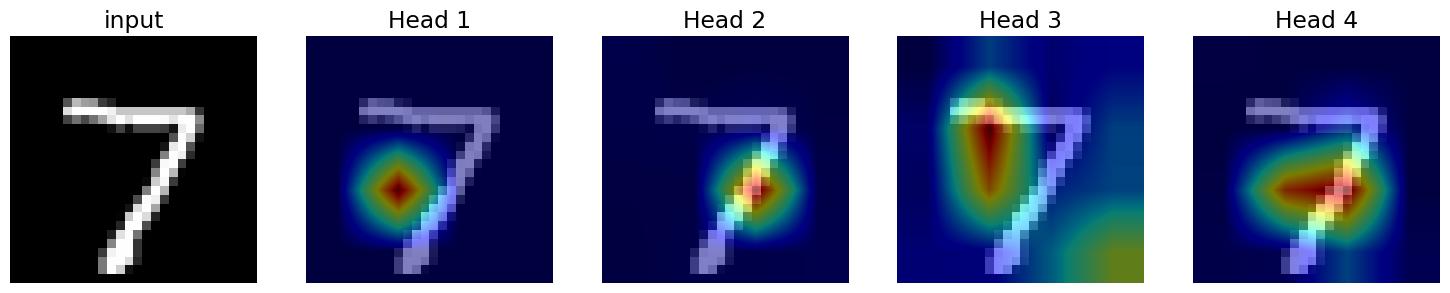

In [47]:
plt.figure(figsize=(3*(n_heads+1), 3))

plt.subplot(1, n_heads+1, 1)
plt.imshow(image.squeeze(0), cmap="gray")
plt.title("input")
plt.axis("off")

for h in range(n_heads):
    cls_attn = weights_list[-1][0, h, 0, 1:]                  # last layer, head h, row 0
    cls_attn = cls_attn.view(grid_size, grid_size).to("cpu").numpy()

    plt.subplot(1, n_heads+1, h+2)
    plt.imshow(image.squeeze(0), cmap="gray")
    plt.imshow(cls_attn, cmap="jet", alpha=0.5,
               extent=(-0.5, 27.5, 27.5, -0.5), interpolation="bilinear")
    plt.title(f"Head {h+1}")
    plt.axis("off")

plt.tight_layout()

### Attention maps for other digits

Let's do the same for 8 test images. Here we take the average over all the layers and all the heads, so each map shows "where the model looked" for that digit.

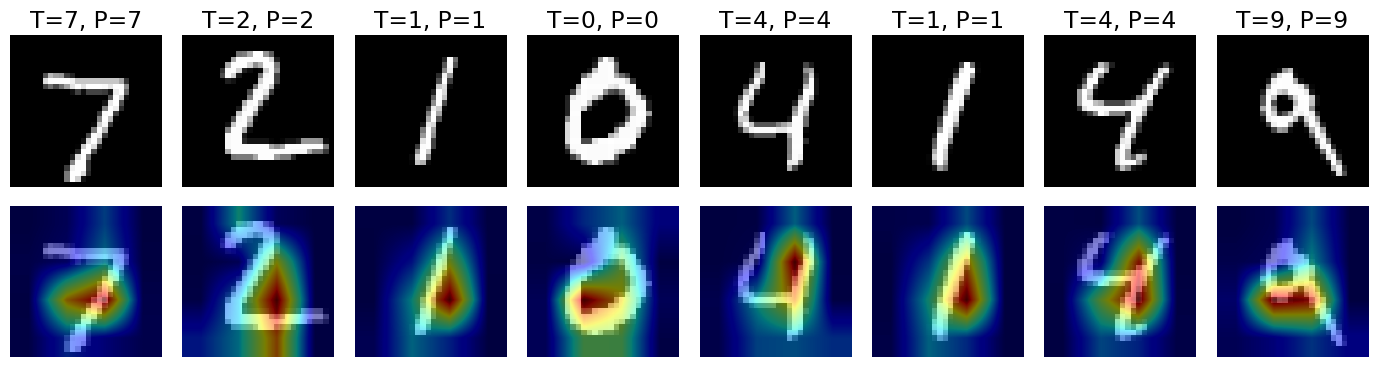

In [48]:
plt.figure(figsize=(14, 4))

for i in range(8):
    image, label = test_dataset[i]
    x = image.unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(x)                   # the model saves the attention weights by itself

    weights_list = model.attn_weights
    pred_label = torch.argmax(pred, dim=1).item()

    # average over all the layers and all the heads
    cls_attn = torch.stack([w[0, :, 0, 1:].mean(dim=0) for w in weights_list]).mean(dim=0)
    cls_attn = cls_attn.view(grid_size, grid_size).to("cpu").numpy()

    # upper row: the input image
    plt.subplot(2, 8, i+1)
    plt.imshow(image.squeeze(0), cmap="gray")
    plt.title(f"T={label}, P={pred_label}")
    plt.axis("off")

    # lower row: the attention map
    plt.subplot(2, 8, i+9)
    plt.imshow(image.squeeze(0), cmap="gray")
    plt.imshow(cls_attn, cmap="jet", alpha=0.5,
               extent=(-0.5, 27.5, 27.5, -0.5), interpolation="bilinear")
    plt.axis("off")

plt.tight_layout()

### What can we learn from these maps?

* The 4 heads look at different places. This is the reason why we use multi-head attention.
* In layer 1, the attention is often spread over the whole image. In the later layers, it usually becomes stronger around the patches that contain the written strokes.
* The corner patches often get small weights, because they are only background.

One caution: attention is a **hint**, not a perfect explanation. After the first layer, each patch already holds information from the other patches. So "the class token looked at patch 5" does not mean "only patch 5 was used". There is a more careful method called *attention rollout*, which multiplies the attention matrices of all the layers together.

## Conclusion
That's it for this week. We built a Vision Transformer from patches, trained it with the MNIST dataset, and looked inside it with attention maps.

Now you can try to improve the test accuracy by changing the hyperparameters, for example `patch_size`, `embed_dim`, `depth`, `heads`, the learning rate and the number of epochs. After you train the model again, please draw the attention maps again too, and see how they changed.